# 4. From the principle to field equations

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 1–3

The transport equations of soft matter are usually introduced one at a time, each
with its own argument: Fick's law for diffusion, the Stokes equation for viscous
flow, Darcy's law for flow through a porous medium. This chapter derives all three
from the Onsager principle. In each case the input is a free energy and a
dissipation function from the tables of Chapter 3, and the output is the familiar
equation, together with something the usual argument does not give: the Einstein
relation between diffusion and friction, the Boltzmann distribution as the state of
rest, and the identification of the pressure as a Lagrange multiplier.

The derivations are checked numerically. A finite-volume solution of the diffusion
equation is compared with the exact solution for particles in a harmonic trap; the
energy balance $\dot A = -2\Phi$ is verified for a non-ideal solution; and a flow
profile is obtained by minimising a discretised Rayleighian directly and compared
with the exact solution of the corresponding differential equation.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import cumulative_trapezoid

try:
    import onsager as on
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import onsager as on

on.use_style()

## 4.1 Diffusion

Particles (colloids, polymer coils, solute molecules) are suspended in a solvent at
rest. Let $c(x, t)$ be their number density and $v(x, t)$ their mean velocity. Take
one space dimension; nothing changes in three.

*State and rates.* The state is the field $c(x)$. Particles are conserved, so the
concentration can only change by particles moving:

$$ \frac{\partial c}{\partial t} = -\frac{\partial (c\,v)}{\partial x} . \tag{4.1} $$

The rate $\dot c$ is thus fixed by the velocity field, and $v(x)$ is the quantity
with respect to which the Rayleighian is minimised. This is the elimination of a
constraint, as in Section 3.4.

*Free energy.* With a free energy density $f(c)$ and an external potential $U(x)$
acting on each particle,

$$ A[c] = \int \big[ f(c) + c\,U(x) \big]\,dx , \qquad
   \frac{\delta A}{\delta c} = f'(c) + U(x) \equiv \mu . $$

The functional derivative is the chemical potential $\mu$. By Eq. (3.2) and
Eq. (4.1),

$$ \dot A = \int \mu\,\dot c\;dx = -\int \mu\,\frac{\partial (c v)}{\partial x}\,dx
          = \int c\,v\,\frac{\partial\mu}{\partial x}\,dx , $$

where the last step is an integration by parts, with no flux through the ends.

*Dissipation function.* Each particle moving at velocity $v$ through the solvent
dissipates $\zeta v^2$, and there are $c\,dx$ particles in $dx$:

$$ \Phi[v] = \frac12\int \zeta\,c\,v^2\,dx . $$

*Minimise.* The Rayleighian is

$$ R[v] = \int \Big[ \tfrac12\zeta\,c\,v^2 + c\,v\,\frac{\partial\mu}{\partial x} \Big]\,dx . $$

It contains no derivatives of $v$, so it is minimised point by point:

$$ \zeta\,v = -\frac{\partial\mu}{\partial x} . \tag{4.2} $$

The friction force on a particle balances the gradient of its chemical potential.
Inserting this in Eq. (4.1),

$$ \frac{\partial c}{\partial t} = \frac{\partial}{\partial x}\Big[ \frac{c}{\zeta}\,\frac{\partial\mu}{\partial x} \Big] . \tag{4.3} $$

Three results are contained in this equation.

**Fick's law, and the diffusion coefficient.** Without an external potential,
$\partial\mu/\partial x = f''(c)\,\partial c/\partial x$, and Eq. (4.3) is the
diffusion equation $\partial c/\partial t = \partial_x[D(c)\,\partial_x c]$ with

$$ D(c) = \frac{c\,f''(c)}{\zeta} = \frac{1}{\zeta}\frac{\partial\Pi}{\partial c} , \tag{4.4} $$

where $\Pi = c f' - f$ is the osmotic pressure. Diffusion is driven by gradients of
osmotic pressure and resisted by friction. (In a concentrated suspension the
friction constant itself depends on concentration, $\zeta = \zeta(c)$, because the
solvent must flow back through the particles; Eq. (4.4) holds as written, and the
effect is taken up in Part III.)

**The Einstein relation.** For a dilute solution $f = k_BT\,c\,(\ln c - 1)$, so
$f'' = k_BT/c$ and

$$ D = \frac{k_BT}{\zeta} . $$

The diffusion coefficient and the friction constant are not independent. The
relation was not assumed; it follows from using the same $\zeta$ for the response to
a concentration gradient and to an external force.

**The Boltzmann distribution.** In a potential, Eq. (4.3) for a dilute solution is
the Smoluchowski equation,

$$ \frac{\partial c}{\partial t} = D\,\frac{\partial}{\partial x}\Big[ \frac{\partial c}{\partial x}
   + \frac{c}{k_BT}\frac{dU}{dx} \Big] . \tag{4.5} $$

The motion stops when $\mu$ is uniform, that is, when $c \propto e^{-U/k_BT}$. Any
equation derived from a free energy relaxes to the equilibrium of that free energy.

## 4.2 Check: particles in a harmonic trap

For $U = \tfrac12 k x^2$ the Smoluchowski equation has an exact solution: a Gaussian
remains a Gaussian, with mean and variance

$$ m(t) = m_0\,e^{-kt/\zeta} , \qquad
   \sigma^2(t) = \frac{k_BT}{k} + \Big(\sigma_0^2 - \frac{k_BT}{k}\Big)e^{-2kt/\zeta} . $$

The mean relaxes as a single particle would (Chapter 1), and the variance relaxes
twice as fast to its Boltzmann value. `on.smoluchowski_fv` solves Eq. (4.3) by a
finite-volume method that conserves the number of particles exactly. Units:
$k_BT = \zeta = k = 1$.

In [2]:
gaussian = lambda x, m, var: np.exp(-(x - m) ** 2 / (2 * var)) / np.sqrt(2 * np.pi * var)
m0, var0 = 2.5, 0.1
times = np.array([0.0, 0.2, 0.6, 1.5, 4.0])

print("  cells   largest error in c     error in mean    error in variance   (all at t = 1.5)")
for n_cells in (140, 280, 560, 1120):
    edges = np.linspace(-6, 8, n_cells + 1)
    xc, c = on.smoluchowski_fv(gaussian(0.5 * (edges[1:] + edges[:-1]), m0, var0), edges, times, U=lambda x: x**2 / 2)
    dx = edges[1] - edges[0]
    mean = np.sum(xc * c[3]) * dx
    var = np.sum((xc - mean) ** 2 * c[3]) * dx
    exact_mean, exact_var = m0 * np.exp(-1.5), 1 + (var0 - 1) * np.exp(-3.0)
    print(f"  {n_cells:5d}      {on.sup_error(c[3], gaussian(xc, exact_mean, exact_var)):.2e}"
          f"            {abs(mean - exact_mean):.1e}          {abs(var - exact_var):.1e}")
x_ou, c_ou = xc, c
print(f"\nnumber of particles at the five times: {np.round(c.sum(axis=1) * dx, 12)}")

t_mom = np.linspace(0, 4, 41)
_, c_mom = on.smoluchowski_fv(gaussian(xc, m0, var0), edges, t_mom, U=lambda x: x**2 / 2)
mean_num = (xc * c_mom).sum(axis=1) * dx
var_num = ((xc - mean_num[:, None]) ** 2 * c_mom).sum(axis=1) * dx

  cells   largest error in c     error in mean    error in variance   (all at t = 1.5)
    140      4.65e-04            3.1e-10          2.4e-03
    280      1.16e-04            3.1e-10          5.9e-04
    560      2.91e-05            3.1e-10          1.5e-04


   1120      7.28e-06            3.1e-10          3.7e-05

number of particles at the five times: [1. 1. 1. 1. 1.]


The numerical solution converges to the exact one as the cells are refined, and the
number of particles does not change. The profile ends as the Boltzmann distribution
of the trap.

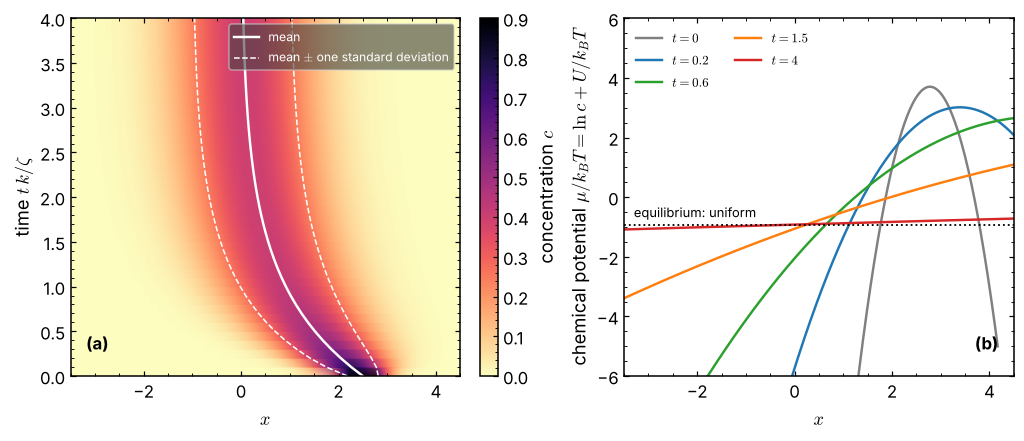

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 3.9))

pcm = ax1.pcolormesh(xc, t_mom, c_mom, cmap="magma_r", shading="gouraud", vmax=0.9)
mean_exact = m0 * np.exp(-t_mom)
sd_exact = np.sqrt(1 + (var0 - 1) * np.exp(-2 * t_mom))
ax1.plot(mean_exact, t_mom, "w-", lw=1.6, label="mean")
ax1.plot(mean_exact - sd_exact, t_mom, "w--", lw=1); ax1.plot(mean_exact + sd_exact, t_mom, "w--", lw=1, label=r"mean $\pm$ one standard deviation")
ax1.set_xlim(-3.5, 4.5); ax1.set_xlabel("$x$"); ax1.set_ylabel(r"time $t\,k/\zeta$")
fig.colorbar(pcm, ax=ax1, label="concentration $c$")
ax1.legend(loc="upper right", fontsize=8, labelcolor="w", facecolor="0.25", frameon=True, framealpha=0.6)
on.panel_label(ax1, "(a)", x=0.04, y=0.12)

for i, col in zip(range(5), ("0.5", "C0", "C2", "C1", "C3")):
    keep = c_ou[i] > 1e-6
    ax2.plot(x_ou[keep], np.log(c_ou[i][keep]) + x_ou[keep] ** 2 / 2, color=col, label=f"$t = {times[i]:g}$")
ax2.axhline(-0.5 * np.log(2 * np.pi), color="k", ls=":", lw=1.2)
ax2.text(-3.3, -0.5 * np.log(2 * np.pi) + 0.25, "equilibrium: uniform", fontsize=8.5)
ax2.set_xlim(-3.5, 4.5); ax2.set_ylim(-6, 6)
ax2.set_xlabel("$x$"); ax2.set_ylabel(r"chemical potential $\mu/k_BT = \ln c + U/k_BT$")
ax2.legend(loc="upper left", fontsize=8.5, ncol=2); on.panel_label(ax2, "(b)", x=0.9, y=0.12)
plt.show()

**Figure 4.1.** **(a)** Concentration of particles released off-centre in a harmonic
trap, as a map in position and time. The cloud drifts to the centre and widens to
its equilibrium width. **(b)** The chemical potential at five times. Particles move
down its slope, Eq. (4.2), so the slope flattens, and the motion ends when the
chemical potential is the same everywhere. A flat chemical potential is the
Boltzmann distribution.

## 4.3 Check: the energy balance of a non-ideal solution

For particles that repel each other, the free energy density acquires a term
proportional to the square of the concentration,

$$ f(c) = k_BT\big[\, c\,(\ln c - 1) + \tfrac12 B\,c^2 \big] , \qquad
   \mu = k_BT\,(\ln c + B\,c) , \qquad D(c) = \frac{k_BT}{\zeta}\,(1 + B\,c) , $$

with $B$ the second virial coefficient. Repulsion makes a concentrated region
spread faster. There is no simple exact solution, but there is an exact statement
to test: the free energy must fall at the rate $2\Phi$,

$$ A(0) - A(t) = \int_0^t 2\Phi\,dt' , \qquad 2\Phi = \int \frac{\zeta\,J^2}{c}\,dx , \quad J = c\,v . $$

The cell computes both sides from the numerical solution, for an ideal solution and
for $B = 4$, starting from the same narrow pulse.

In [4]:
edges_b = np.linspace(-12, 12, 2401)
dx_b = edges_b[1] - edges_b[0]
xb = 0.5 * (edges_b[1:] + edges_b[:-1])
t_b = np.linspace(0, np.sqrt(3.0), 1501) ** 2          # finer at early times, when the pulse is narrow
balance = {}
for B in (0.0, 4.0):
    _, cb = on.smoluchowski_fv(gaussian(xb, 0.0, 0.02), edges_b, t_b, mu_excess=lambda c: B * c,
                               rtol=1e-10, atol=1e-13)
    cpos = np.maximum(cb, 1e-300)
    A = np.sum(cb * (np.log(cpos) - 1) + 0.5 * B * cb**2, axis=1) * dx_b
    c_face = 0.5 * (cb[:, 1:] + cb[:, :-1])
    J = -(np.diff(cb, axis=1) + c_face * np.diff(B * cb, axis=1)) / dx_b
    two_Phi = np.sum(J**2 / np.maximum(c_face, 1e-300), axis=1) * dx_b
    dissipated = cumulative_trapezoid(two_Phi, t_b, initial=0.0)
    width = np.sqrt(np.sum(xb**2 * cb, axis=1) * dx_b)
    balance[B] = (A[0] - A, dissipated, width, cb)
    print(f"B = {B:.0f}:  free energy lost = {A[0] - A[-1]:.4f},  dissipated = {dissipated[-1]:.4f},"
          f"  relative difference = {abs(dissipated[-1] / (A[0] - A[-1]) - 1):.1e},"
          f"  width at t = 3: {width[-1]:.3f}")
print(f"ideal solution, exact width at t = 3: {math.sqrt(0.02 + 2 * 3.0):.3f}")

B = 0:  free energy lost = 2.8536,  dissipated = 2.8530,  relative difference = 2.1e-04,  width at t = 3: 2.454


B = 4:  free energy lost = 6.7887,  dissipated = 6.7883,  relative difference = 6.6e-05,  width at t = 3: 2.831
ideal solution, exact width at t = 3: 2.454


The two sides agree to better than one part in a thousand, the remaining
difference being the discretisation of the narrow initial pulse, and the repelling
particles spread further in the same time. The width of the ideal pulse matches the exact
$\sqrt{\sigma_0^2 + 2Dt}$.

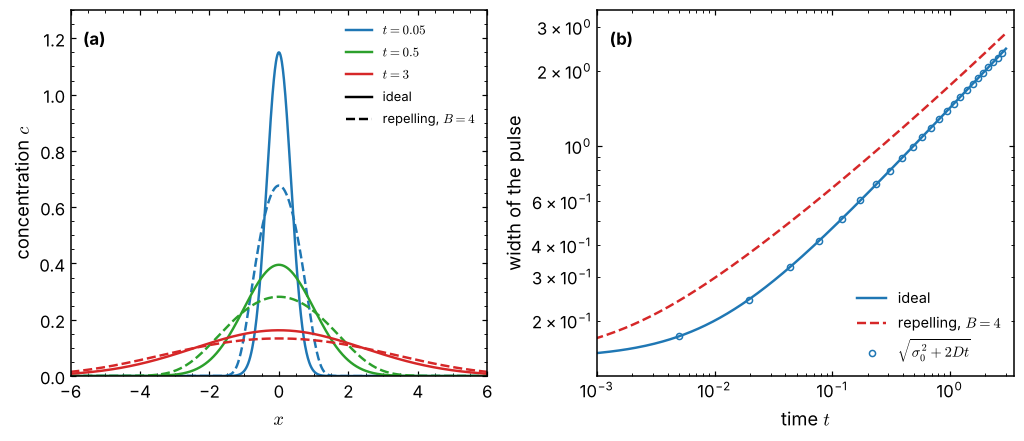

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 3.9))

for tm, col in ((0.05, "C0"), (0.5, "C2"), (3.0, "C3")):
    k_ = np.argmin(np.abs(t_b - tm))
    ax1.plot(xb, balance[0.0][3][k_], "-", color=col, label=f"$t = {tm:g}$")
    ax1.plot(xb, balance[4.0][3][k_], "--", color=col)
ax1.plot([], [], "k-", label="ideal"); ax1.plot([], [], "k--", label="repelling, $B = 4$")
ax1.set_xlim(-6, 6); ax1.set_ylim(0, 1.3)
ax1.set_xlabel("$x$"); ax1.set_ylabel("concentration $c$")
ax1.legend(loc="upper right", fontsize=8.5); on.panel_label(ax1, "(a)")

ax2.loglog(t_b[1:], balance[0.0][2][1:], "-", color="C0", label="ideal")
ax2.loglog(t_b[1:], balance[4.0][2][1:], "--", color="C3", label="repelling, $B = 4$")
ax2.loglog(t_b[1::60], np.sqrt(0.02 + 2 * t_b[1::60]), "o", color="C0", mfc="none", ms=4, label=r"$\sqrt{\sigma_0^2 + 2Dt}$")
ax2.set_xlim(1e-3, 3.5); ax2.set_ylim(0.12, 3.5)
ax2.set_xlabel("time $t$"); ax2.set_ylabel("width of the pulse")
ax2.legend(loc="lower right"); on.panel_label(ax2, "(b)")
plt.show()

**Figure 4.2.** **(a)** Spreading of a narrow pulse for ideal (solid) and repelling
(dashed) particles. Repulsion flattens the dense centre of the pulse first.
**(b)** Width of the pulse. The repelling particles gain their lead early, while
the pulse is dense, and keep it; at late times, when the solution is dilute
everywhere, both widths grow as $\sqrt{2Dt}$.

## 4.4 The Stokes equation

For a viscous liquid the rates are the velocities of the fluid elements, the field
$\mathbf v(\mathbf r)$.

*Dissipation function* (first row of the first table of Section 3.2):

$$ \Phi[\mathbf v] = \frac{\eta}{4}\int \sum_{i,j}\Big(\frac{\partial v_i}{\partial x_j}
   + \frac{\partial v_j}{\partial x_i}\Big)^2\,dV . $$

*Free energy.* Under gravity the potential energy changes at the rate
$\dot A = -\int \rho\,\mathbf g\cdot\mathbf v\,dV$.

*Constraint.* The liquid is incompressible: $\nabla\cdot\mathbf v = 0$ at every
point. There is one constraint for each point, so the multiplier is a field,
$p(\mathbf r)$, and the function to minimise is

$$ \tilde R[\mathbf v] = \Phi[\mathbf v] - \int \rho\,\mathbf g\cdot\mathbf v\,dV
   - \int p\,\nabla\cdot\mathbf v\,dV . $$

*Minimise.* Change $\mathbf v$ to $\mathbf v + \delta\mathbf v$, with $\delta\mathbf v
= 0$ on the walls. Writing $e_{ij} = \partial_j v_i + \partial_i v_j$,

$$ \delta\Phi = \frac{\eta}{2}\int \sum_{i,j} e_{ij}\,\big(\partial_j\delta v_i + \partial_i\delta v_j\big)\,dV
             = \eta\int \sum_{i,j} e_{ij}\,\partial_j\delta v_i\,dV
             = -\eta\int \sum_{i,j} \partial_j e_{ij}\;\delta v_i\,dV , $$

using the symmetry of $e_{ij}$ and then an integration by parts. Now
$\sum_j\partial_j e_{ij} = \nabla^2 v_i + \partial_i(\nabla\cdot\mathbf v) = \nabla^2 v_i$.
The last term of $\tilde R$ varies as $-\int p\,\nabla\cdot\delta\mathbf v\,dV =
\int \nabla p\cdot\delta\mathbf v\,dV$. Altogether

$$ \delta\tilde R = \int \big( -\eta\nabla^2\mathbf v + \nabla p - \rho\,\mathbf g \big)\cdot\delta\mathbf v\;dV = 0
   \quad\Longrightarrow\quad
   \eta\nabla^2\mathbf v - \nabla p + \rho\,\mathbf g = 0 . \tag{4.6} $$

This is the Stokes equation. The multiplier that enforces incompressibility is the
pressure, exactly as the multipliers of Section 3.4 were the hydrostatic pressures
in the two vessels.

## 4.5 Darcy's law, and a combination

When a liquid flows through a porous solid at rest (a packed bed, a gel network, a
soil), the dominant friction is between liquid and solid: the third row of the same
table, $\Phi = \tfrac12\int\xi\,v^2\,dV$ with $\xi = \eta/\kappa$, where $\mathbf v$ is
now the velocity averaged over many pores. The same steps give

$$ \xi\,\mathbf v + \nabla p - \rho\,\mathbf g = 0
   \quad\Longrightarrow\quad
   \mathbf v = -\frac{\kappa}{\eta}\,\big(\nabla p - \rho\,\mathbf g\big) , \tag{4.7} $$

which is Darcy's law.

Dissipation functions add. If both mechanisms act, viscous stress in the liquid
and friction against the solid, the dissipation function is the sum of the two, and
the same minimisation gives

$$ \eta\nabla^2\mathbf v - \xi\,\mathbf v - \nabla p + \rho\,\mathbf g = 0 , \tag{4.8} $$

known as the Brinkman equation. (In a real porous medium the viscosity in the first
term is an effective one, of the order of $\eta$ but not equal to it.) Nothing had to
be re-derived. This is the practical
content of "scalars are easier than forces" (Section 1.2): to include a new
mechanism, add its term to $\Phi$ or to $A$.

## 4.6 Check: minimising a discretised Rayleighian

A channel $-1 < y < 1$ is filled with a porous medium and a pressure gradient $G$
drives a flow $u(y)$ along it, with no slip at the walls. Per unit area of wall the
Rayleighian is

$$ R[u] = \int_{-1}^{1} \Big[ \frac{\eta}{2}\Big(\frac{du}{dy}\Big)^2 + \frac{\xi}{2}\,u^2 - G\,u \Big]\,dy . $$

Its minimum satisfies Eq. (4.8), $\eta u'' - \xi u = -G$, whose solution is

$$ u(y) = \frac{G}{\xi}\Big[ 1 - \frac{\cosh\alpha y}{\cosh\alpha} \Big] , \qquad \alpha = \sqrt{\xi/\eta} . $$

For $\alpha \to 0$ this is the parabola of Poiseuille flow; for large $\alpha$ it is
the uniform Darcy velocity $G/\xi$, with layers of thickness $1/\alpha = \sqrt\kappa$
at the walls.

The cell does not use the differential equation. It represents $u$ by its values at
$N$ points, writes $R$ as a sum, and finds the values that make the sum smallest.
Since the sum is quadratic in the unknowns, $R = \tfrac12\mathbf u^{\mathsf T}H\mathbf u -
\mathbf g\cdot\mathbf u$, its minimum is the solution of $H\mathbf u = \mathbf g$.

In [6]:
def minimise_channel(alpha, N):
    """Values of u at N interior points that minimise the discretised R (eta = G = 1)."""
    y = np.linspace(-1, 1, N + 2)
    dy = y[1] - y[0]
    xi = alpha**2
    # R = sum over intervals of (1/2)(u_{i+1} - u_i)^2 / dy  +  sum over points of (xi u_i^2 / 2 - u_i) dy
    H = (np.diag(np.full(N, 2 / dy + xi * dy)) - np.diag(np.full(N - 1, 1 / dy), 1) - np.diag(np.full(N - 1, 1 / dy), -1))
    u = np.linalg.solve(H, np.full(N, dy))
    return y, np.concatenate(([0.0], u, [0.0]))


def brinkman_exact(y, alpha):
    if alpha == 0:
        return 0.5 * (1 - y**2)
    return (1 - np.cosh(alpha * y) / np.cosh(alpha)) / alpha**2


Ns = np.array([10, 20, 40, 80, 160])
print("largest difference between the minimiser of the discrete R and the exact profile")
print("    N     alpha = 0     alpha = 3     alpha = 10")
err_ch = {0.0: [], 3.0: [], 10.0: []}
for N in Ns:
    for al in err_ch:
        y, u = minimise_channel(al, N)
        err_ch[al].append(on.sup_error(u, brinkman_exact(y, al)))
    print(f"  {N:4d}    {err_ch[0.0][-1]:.2e}      {err_ch[3.0][-1]:.2e}      {err_ch[10.0][-1]:.2e}")
for al in (3.0, 10.0):
    print(f"alpha = {al:g}: slope against the spacing = {on.loglog_slope(2 / (Ns + 1), err_ch[al])[0]:.2f}")

largest difference between the minimiser of the discrete R and the exact profile
    N     alpha = 0     alpha = 3     alpha = 10
    10    5.00e-16      5.33e-04      3.34e-04
    20    5.00e-16      1.49e-04      1.28e-04
    40    7.22e-16      3.92e-05      3.57e-05
    80    1.11e-15      1.01e-05      9.29e-06
   160    1.52e-14      2.55e-06      2.36e-06
alpha = 3: slope against the spacing = 1.99
alpha = 10: slope against the spacing = 1.87


For $\alpha = 0$ the minimiser of the discrete sum coincides with the parabola at
the grid points to rounding error (the difference formula is exact for a parabola).
For $\alpha > 0$ it converges to the exact profile as the square of the spacing
(for $\alpha = 10$ the coarser grids do not yet resolve the thin layers at the walls,
and the measured slope, 1.87, is still approaching 2).
The flow profile was obtained from the two scalars alone.

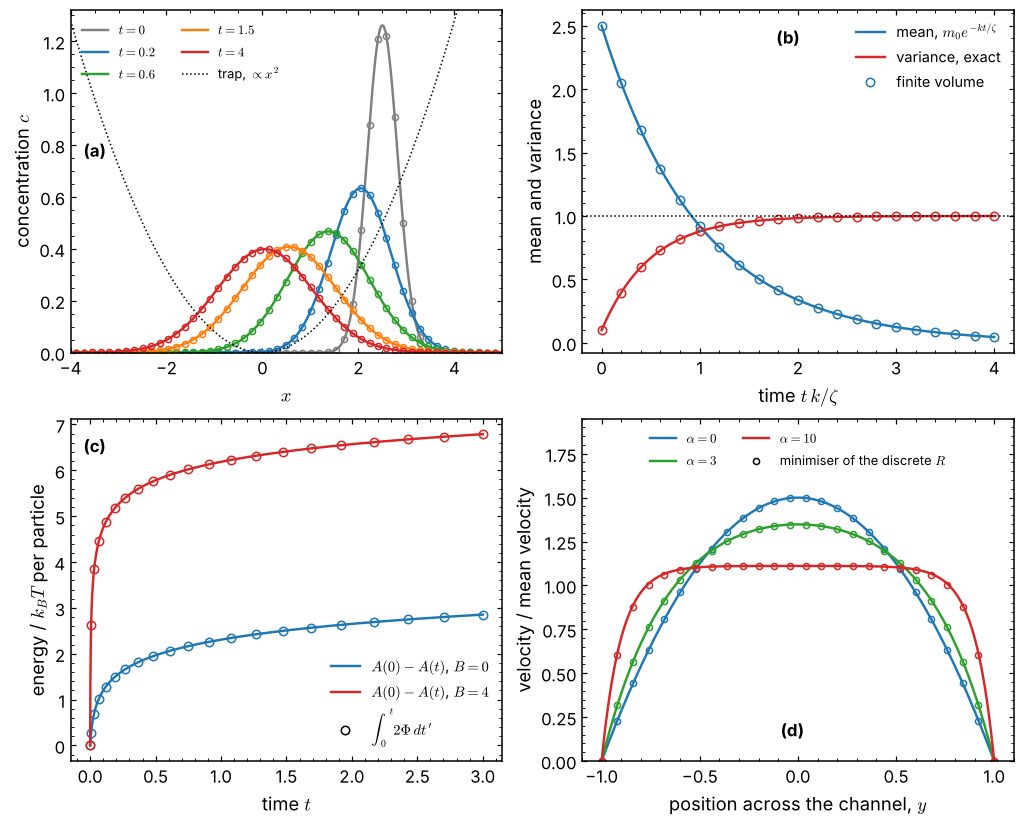

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.4))

ax = axes[0, 0]
xs = np.linspace(-4, 5, 600)
for i, c in zip(range(5), ("0.5", "C0", "C2", "C1", "C3")):
    tt = times[i]
    m, var = m0 * np.exp(-tt), 1 + (var0 - 1) * np.exp(-2 * tt)
    ax.plot(xs, gaussian(xs, m, var), "-", color=c, label=f"$t = {tt:g}$")
    ax.plot(x_ou[::14], c_ou[i][::14], "o", color=c, mfc="none", ms=4)
ax.plot(xs, 0.08 * xs**2, "k:", lw=1, label=r"trap, $\propto x^2$")
ax.set_xlim(-4, 5); ax.set_ylim(0, 1.32)
ax.set_xlabel("$x$"); ax.set_ylabel("concentration $c$")
ax.legend(loc="upper left", fontsize=8.5, ncol=2); on.panel_label(ax, "(a)", x=0.03, y=0.62)

ax = axes[0, 1]
tf = np.linspace(0, 4, 200)
ax.plot(tf, m0 * np.exp(-tf), "-", color="C0", label=r"mean, $m_0e^{-kt/\zeta}$")
ax.plot(tf, 1 + (var0 - 1) * np.exp(-2 * tf), "-", color="C3", label="variance, exact")
ax.plot(t_mom[::2], mean_num[::2], "o", color="C0", mfc="none", label="finite volume")
ax.plot(t_mom[::2], var_num[::2], "o", color="C3", mfc="none")
ax.axhline(1, color="k", ls=":", lw=1)
ax.set_xlabel(r"time $t\,k/\zeta$"); ax.set_ylabel("mean and variance")
ax.legend(loc="upper right"); on.panel_label(ax, "(b)", x=0.45)

ax = axes[1, 0]
for B, c in ((0.0, "C0"), (4.0, "C3")):
    lost, diss, _, _ = balance[B]
    ax.plot(t_b, lost, "-", color=c, label=f"$A(0) - A(t)$, $B = {B:g}$")
    ax.plot(t_b[::75], diss[::75], "o", color=c, mfc="none")
ax.plot([], [], "o", color="k", mfc="none", label=r"$\int_0^t 2\Phi\,dt'$")
ax.set_xlabel("time $t$"); ax.set_ylabel("energy / $k_BT$ per particle")
ax.legend(loc="lower right"); on.panel_label(ax, "(c)")

ax = axes[1, 1]
yf = np.linspace(-1, 1, 400)
for al, c in ((0.0, "C0"), (3.0, "C2"), (10.0, "C3")):
    mean_u = np.trapezoid(brinkman_exact(yf, al), yf) / 2
    ax.plot(yf, brinkman_exact(yf, al) / mean_u, "-", color=c, label=rf"$\alpha = {al:g}$")
    y, u = minimise_channel(al, 24)
    ax.plot(y, u / mean_u, "o", color=c, mfc="none", ms=4)
ax.plot([], [], "o", color="k", mfc="none", ms=4, label="minimiser of the discrete $R$")
ax.set_xlabel("position across the channel, $y$"); ax.set_ylabel("velocity / mean velocity")
ax.set_ylim(0, 1.95); ax.legend(loc="upper center", ncol=2, fontsize=8.5); on.panel_label(ax, "(d)", x=0.46, y=0.12)
plt.show()

**Figure 4.3.** **(a)** Particles in a harmonic trap: exact solution of the Smoluchowski equation
(lines) and finite-volume solution (circles). The profile relaxes to the Boltzmann
distribution. **(b)** Mean and variance of the same profiles. **(c)** Spreading of a
narrow pulse: free energy lost (lines) and energy dissipated (circles), for an ideal
solution and for repelling particles. **(d)** Flow through a channel filled with a
porous medium, from Poiseuille flow ($\alpha = 0$) to Darcy flow with wall layers
($\alpha = 10$): exact profiles and the values that minimise the discretised
Rayleighian with 24 points.

## Summary

* For conserved particles the rate with respect to which $R$ is minimised is the
  velocity field; the concentration follows from conservation. The result,
  $\zeta v = -\partial\mu/\partial x$, gives the diffusion equation with
  $D = \zeta^{-1}\partial\Pi/\partial c$.
* The Einstein relation $D = k_BT/\zeta$ and the Boltzmann distribution are
  consequences, not assumptions.
* With incompressibility imposed by a multiplier field, viscous dissipation gives the
  Stokes equation and friction against a porous solid gives Darcy's law. The
  multiplier is the pressure.
* Dissipation functions add: two mechanisms together give the Brinkman equation with
  no further derivation.

## Exercises

Sample solutions are in [`solutions/part1_principle/04_solutions.ipynb`](../../solutions/part1_principle/04_solutions.ipynb).

1. **Excluded volume.** For hard rods on a line, $f = k_BT\,[c\ln c - c - c\ln(1 - bc)]$,
   where $b$ is the length of a rod. Show that $\Pi = k_BT\,c/(1 - bc)$ and
   $D = (k_BT/\zeta)/(1 - bc)^2$. Solve Eq. (4.3) with `on.smoluchowski_fv`
   (`mu_excess = lambda c: -np.log(1 - b*c) + b*c/(1 - b*c)`) and compare the
   spreading of a pulse with the ideal case.
2. **Sedimentation equilibrium.** For particles of buoyant weight $mg$ in a dilute
   suspension, $U = mgz$. Show from Eq. (4.3) that the equilibrium profile is
   $c \propto e^{-z/\ell_g}$ with $\ell_g = k_BT/mg$, and that a uniform suspension of
   height $H \gg \ell_g$ takes a time of order $H\zeta/mg$ to settle. Confirm both
   numerically.
3. **Flow rate with porous drag.** Show that the flow rate of the channel of
   Section 4.6 is $Q = (2G/\xi)\,(1 - \tanh\alpha/\alpha)$, and recover the Poiseuille and
   Darcy limits.
4. **Two dimensions.** Repeat the derivation of Section 4.1 in two dimensions with
   an anisotropic friction, $\Phi = \tfrac12\int c\,(\zeta_x v_x^2 + \zeta_y v_y^2)\,dS$,
   and obtain the anisotropic diffusion equation.

## Suggested references

* M. Doi, *Soft Matter Physics* (Oxford University Press, 2013).
* M. Doi and S. F. Edwards, *The Theory of Polymer Dynamics* (Oxford University Press, 1986).
* W. B. Russel, D. A. Saville and W. R. Schowalter, *Colloidal Dispersions* (Cambridge University Press, 1989).
* G. K. Batchelor, *An Introduction to Fluid Dynamics* (Cambridge University Press, 1967).
* M. Doi, "Onsager's variational principle in soft matter", *J. Phys.: Condens. Matter* **23**, 284118 (2011).

---

**Previous:** [3. Writing the two functions](03_writing_the_two_functions.ipynb) &nbsp;·&nbsp;
**Next:** [5. The approximation method](05_approximation_method.ipynb)